In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan
df.loc[99, 'study_hours'] = 50
df.loc[98, 'attendance'] = -10

print(df)


    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [2]:
#PART A: INSPECT AND CLEAN 
#A1. Try to identify the outlier in study_hours and remove or cap it
# Data inspection helps us find missing values and unusual records before analysis.

print("Missing values:")
print(df.isnull().sum())

print("\nOutlier record:")
print(df[df['study_hours'] == 50])

print("\nInvalid attendance record:")
print(df[df['attendance'] < 0])


Missing values:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

Outlier record:
    study_hours  attendance  previous_mark  final_score
99         50.0   73.570297      79.444433     46.41447

Invalid attendance record:
    study_hours  attendance  previous_mark  final_score
98     5.010227       -10.0      82.192932    44.045627


In [3]:

# here is try to clean the data 
df['study_hours'] = df['study_hours'].fillna(
    df['study_hours'].median()
)

Q1 = df['study_hours'].quantile(0.25)
Q3 = df['study_hours'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

df['study_hours'] = df['study_hours'].clip(upper=upper_limit)

df.loc[df['attendance'] < 0, 'attendance'] = np.nan

df['attendance'] = df['attendance'].fillna(
    df['attendance'].median()
)

print("Remaining missing values:")
print(df.isnull().sum())

print("\nMaximum study hours after cleaning:")
print(df['study_hours'].max())


Remaining missing values:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64

Maximum study hours after cleaning:
8.609995563455456


The value 50 is an outlier because it is unusually high compared with the other students' study hours. I chose to cap it using the IQR method rather than delete the entire student record, because the other information in that row may still be useful. Missing values are filled with the median, and impossible attendance is corrected.


In [4]:

X = df[['study_hours', 'attendance', 'previous_mark']]
y = df['final_score']

print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())
# The feature matrix contains the information used to make predictions
#while the target contains the value we want to predict.

Dataset shape: (100, 4)
Feature matrix shape: (100, 3)
Target shape: (100,)

Numerical columns:
['study_hours', 'attendance', 'previous_mark', 'final_score']


Dataset shape: (100, 4) — 100 students and four columns.

Feature matrix shape: (100, 3) — 100 students and three input features.

Numerical columns: study_hours, attendance, previous_mark, and final_score.

Target variable: final_score.

In [5]:
# B. Calculate the mean, median, and standard deviation for all columns
#The mean shows the average
#The median shows the middle value
#The standard deviation measures how spread out the values are.
statistics = df.agg(['mean', 'median', 'std'])

print(statistics)


        study_hours  attendance  previous_mark  final_score
mean       4.779676   85.227190      70.973444    42.691957
median     4.812342   85.996514      71.465436    42.763014
std        1.814480    9.536937      16.264243     6.086797


Study hours: The median is less affected by extreme values than the mean, so it can better represent a typical student's study hours when outliers are present.



Attendance: The mean and median help show the typical attendance level. The standard deviation tells us whether attendance varies greatly among students.



Final score: The mean describes the average final score, while the standard deviation indicates how much students' scores differ from one another.

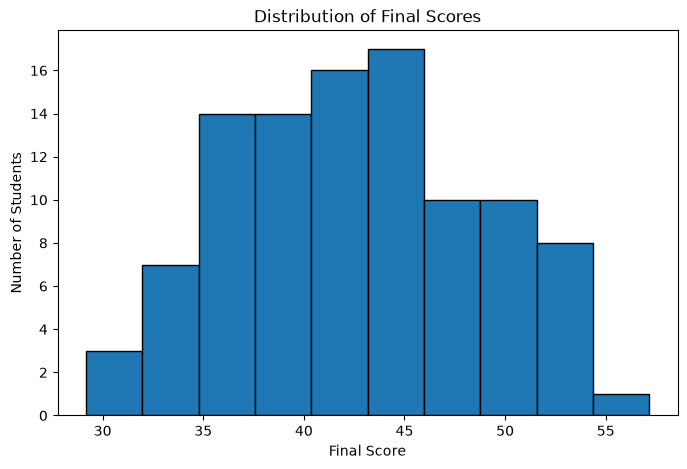

In [6]:
# C. Visulaize it
# A histogram groups scores into intervals and shows how many students fall within each interval.
plt.figure(figsize=(8, 5))

plt.hist(df['final_score'], bins=10, edgecolor='black')

plt.xlabel('Final Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Final Scores')

plt.show()


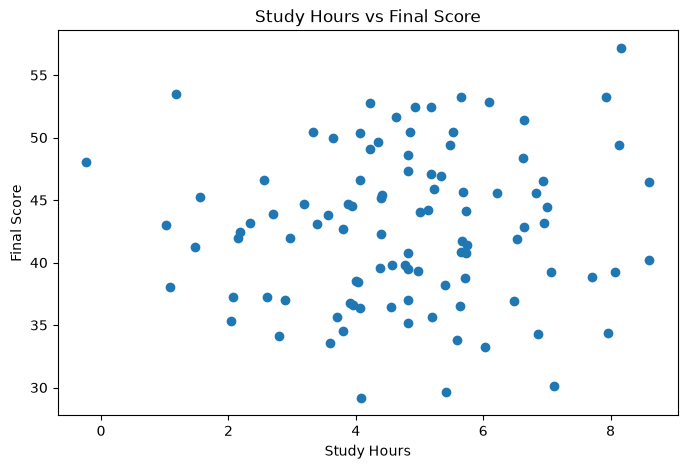

In [7]:
# A scatter plot helps us see whether students who study more hours tend to achieve higher final scores.
plt.figure(figsize=(8, 5))

plt.scatter(df['study_hours'], df['final_score'])

plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.title('Study Hours vs Final Score')

plt.show()


Look at the direction of the points. If they generally rise from left to right, the relationship is positive: students who study more tend to have higher scores. The points will not necessarily lie on a straight line because other factors and random variation also affect scores.

In [8]:
#D. CORRELATION AND CAUSALITY 
# Pearson correlation measures the strength and direction of a linear relationship between two numerical variables.
correlation = df['study_hours'].corr(df['final_score'])

print("Pearson correlation:", correlation)


Pearson correlation: 0.061777609938368595


No. Correlation does not guarantee that a student who studies for 10 hours will receive a specific score. Correlation describes a relationship between variables; it does not predict an exact outcome for every individual or prove causation.
A potential confounding variable is previous academic performance (previous_mark). Students with stronger prior knowledge might both study differently and achieve higher scores. Attendance may also affect the relationship.


In [9]:
#E VECTORS AND DOT PRODUCT
# Pearson correlation measures the strength and direction of a linear relationship between two numerical variables.

x = df.loc[1, ['study_hours', 'attendance', 'previous_mark']].to_numpy(dtype=float)

w = np.array([0.5, 0.2, 0.4])
b = 5

prediction = np.dot(w, x) + b

print("Student feature vector:", x)
print("Weight vector:", w)
print("Bias:", b)
print("Predicted score:", prediction)


Student feature vector: [ 4.8123416  80.79354677 78.4117679 ]
Weight vector: [0.5 0.2 0.4]
Bias: 5
Predicted score: 54.9295873106944


K-Nearest Neighbors (KNN) uses distances to identify similar data points. In the original dataset, study_hours typically ranges around a few hours, while previous_mark is measured in marks, often around 70. Because the numerical ranges differ, previous marks could dominate the distance calculation and make study hours contribute relatively little. Standardization helps both features contribute more comparably to distance calculations.
